Device: cpu


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

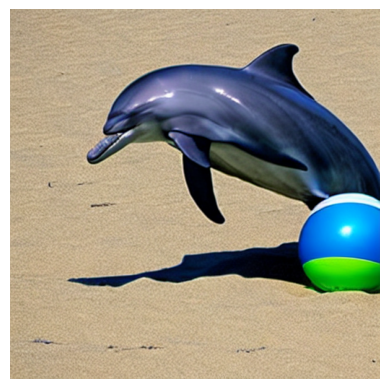

In [4]:
# Import libraries
import torch
from diffusers import StableDiffusionPipeline
from PIL import Image
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
# The pre-trained model to use (Stable Diffusion v1.5)
model_id = "runwayml/stable-diffusion-v1-5"
# Load model and move the pipeline to the selected device (GPU or CPU)
pipeline = StableDiffusionPipeline.from_pretrained(model_id)
pipeline = pipeline.to(device)

# Define the text prompt that describes the image to generate
prompt = "A photo of a dolphin with a stop sign in its mouth on top of a beach ball"
# Set guidance scale: higher values make the image more closely follow the prompt
guidance_scale = 9.5
# Set the number of denoising steps (higher = better quality, but slower)
steps = 50
num_images = 1
# Generate image(s)
result = pipeline(
prompt=prompt,
num_images_per_prompt=num_images,
guidance_scale=guidance_scale,
num_inference_steps = steps
)
image = result.images[0]

# Display the generated image
plt.imshow(image)
plt.axis('off')
plt.show()
image.save("generated_image.png")

In [5]:
import os
import math
import time
import random
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from torchvision import datasets, transforms, utils as vutils
from PIL import Image, ImageFilter
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


class PrepareDataset(Dataset):
    def __init__(self, root, split="train", size=256, hflip=True, in_ch="auto"):
        self.root = Path(root) / split
        self.paths = sorted(
            [p for p in self.root.iterdir() if p.suffix.lower() in {".jpg", ".png", ".jpeg"}]
        )
        self.size = size
        self.hflip = hflip
        self.in_ch = in_ch

        self.resize = transforms.Resize((size, size), interpolation=Image.BICUBIC)
        self.to_tensor = transforms.ToTensor()

        self.norm1 = transforms.Normalize([0.5], [0.5])
        self.norm3 = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])

    def __len__(self):
        return len(self.paths)

    def _split_ab(self, img):
        w, h = img.size
        A = img.crop((0, 0, w // 2, h))
        B = img.crop((w // 2, 0, w, h))
        return A, B

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        A_img, B_img = self._split_ab(img)

        A_img = self.resize(A_img)
        B_img = self.resize(B_img)

        if self.hflip and random.random() < 0.5:
            A_img = A_img.transpose(Image.FLIP_LEFT_RIGHT)
            B_img = B_img.transpose(Image.FLIP_LEFT_RIGHT)

        if self.in_ch == 1:
            A_t = transforms.functional.rgb_to_grayscale(
                self.to_tensor(A_img), num_output_channels=1
            )
            A_t = self.norm1(A_t)
        else:
            A_t = self.norm3(self.to_tensor(A_img))

        B_t = self.norm3(self.to_tensor(B_img))
        return A_t, B_t


# Initialize datasets and loaders
root = "C:\\Users\\792497\\Workspace\\cv_test\\edge2shoes"

train_ds = PrepareDataset(root, split="train", size=256, hflip=True, in_ch=3)
val_ds = PrepareDataset(root, split="val", size=256, hflip=False, in_ch=3)

train_loader = DataLoader(
    train_ds, batch_size=8, shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=8, shuffle=False, num_workers=2, pin_memory=True
)

print("Dataset sizes:", len(train_ds), "training images,", len(val_ds), "validation images.")

Device: cpu
Dataset sizes: 49825 training images, 200 validation images.


In [2]:
import torchvision.utils as vutils
import matplotlib.pyplot as plt

# Fetch one batch of data
A, B = next(iter(train_loader))
grid = vutils.make_grid(
    torch.cat([(A[:8] + 1) / 2, (B[:8] + 1) / 2], dim=0),
    nrow=8,
)

plt.figure(figsize=(12, 4))
plt.axis("off")
plt.imshow(grid.permute(1, 2, 0).cpu())  # convert CHW tensor to HWC
plt.show()

NameError: name 'train_loader' is not defined

In [ ]:
# Building blocks for the U-Net generator:
def conv_block(in_c, out_c, k=4, s=2, p=1, norm=True, activation='lrelu'):
"""Args:
in_c, out_c: input/output channels
k,s,p: kernel, stride, padding
norm: whether to use InstanceNorm
activation function: 'lrelu' or 'relu'
A convolutional block: Conv2d -> (InstanceNorm) -> LeakyReLU/ReLU
"""
× ×
×
lab_02.md 2026-10-04
8 / 17
layers = [nn.Conv2d(in_c, out_c, kernel_size=k, stride=s, padding=p,
bias=not norm)]
if norm:
layers.append(nn.InstanceNorm2d(out_c))
if activation == 'lrelu':
layers.append(nn.LeakyReLU(0.2, inplace=True))
elif activation == 'relu':
layers.append(nn.ReLU(inplace=True))
return nn.Sequential(*layers)
def deconv_block(in_c, out_c, k=4, s=2, p=1, dropout=False):
"""A transposed-convolution block: ConvTranspose2d -> InstanceNorm ->
ReLU -> (Dropout optional)"""
layers = [
nn.ConvTranspose2d(in_c, out_c, kernel_size=k, stride=s, padding=p,
bias=False),
nn.InstanceNorm2d(out_c),
nn.ReLU(inplace=True),
]
if dropout:
layers.append(nn.Dropout(0.5))
return nn.Sequential(*layers)

In [ ]:
# U-Net Generator (encoder-decoder with skip connections):
class UNetGenerator(nn.Module):
def __init__(self, in_ch=3, out_ch=3, nf=64):
"""Args:
in_ch: number of input channels (1 or 3 for edges)
out_ch: number of output channels (3 for RGB photo)
nf: number of filters in the conv layer
"""
super().__init__()
# Encoder (Downsampling path)
self.e1 = conv_block(in_ch, nf, norm=False) # Output: nf
features, (H/2 x W/2)
self.e2 = conv_block(nf, nf*2) # Output: nf*2
features (H/4 x W/4)
self.e3 = conv_block(nf*2, nf*4) # (H/8 x W/8)
self.e4 = conv_block(nf*4, nf*8) # (H/16 x W/16)
self.e5 = conv_block(nf*8, nf*8) # (H/32 x W/32)
self.e6 = conv_block(nf*8, nf*8, norm=False) # (H/64 x W/64)
bottleneck
# Decoder (Upsampling path with skip connections; dropout on deeper
layers)
self.d1 = deconv_block(nf*8, nf*8, dropout=True) # Upsample
bottleneck (H/32)
self.d2 = deconv_block(nf*16, nf*8, dropout=True) # concat with
e5 -> (H/16)
self.d3 = deconv_block(nf*16, nf*4) # concat with
lab_02.md 2026-10-04
9 / 17
e4 -> (H/8)
self.d4 = deconv_block(nf*8, nf*2) # concat with
e3 -> (H/4)
self.d5 = deconv_block(nf*4, nf) # concat with
e2 -> (H/2)
self.d6 = nn.Sequential( # concat
with e1 -> (H x W)
nn.ConvTranspose2d(nf*2, out_ch, kernel_size=4, stride=2,
padding=1),
nn.Tanh())
def forward(self, x):
# Encoder forward pass
e1 = self.e1(x) # e1: first conv output
e2 = self.e2(e1)
e3 = self.e3(e2)
e4 = self.e4(e3)
e5 = self.e5(e4)
e6 = self.e6(e5) # e6: bottleneck features
# Decoder forward pass with skip connections
d1 = self.d1(e6) # upsample bottleneck
d1 = torch.cat([d1, e5], dim=1) # concat skip from e5
d2 = self.d2(d1)
d2 = torch.cat([d2, e4], dim=1) # skip from e4
d3 = self.d3(d2)
d3 = torch.cat([d3, e3], dim=1) # skip from e3
d4 = self.d4(d3)
d4 = torch.cat([d4, e2], dim=1) # skip from e2
d5 = self.d5(d4)
d5 = torch.cat([d5, e1], dim=1) # skip from e1
out = self.d6(d5) # final output layer
return out